# Phase 2: From one snapshot to a year of quarters

Phase 1 trained five models on a single Inside Airbnb snapshot and found that **Random Forest** with 48 listing features prices best. Prices move during the year, so this notebook asks three questions:

1. **Does a model trained on one quarter (June) still work in later quarters?** We test it on September listings it has never seen.
2. **Do time and zone features help?** We pool the quarters, add *time* features (quarter, how long a listing has been live) and *zone* features (distance ring and geographic clusters), and measure the gain.
3. **How do the weights of each parameter change between quarters?** We fit Lasso per quarter and compare coefficients, and we test recency weighting (newer quarters count more).

### The four snapshots

| File | Snapshot | Listings | Prices |
|---|---|---|---|
| `listings_2025Q4_dec.csv` | Dec 2025 (latest review 1 Jan 2026) | 3,706 | none published |
| `listings_2026Q1_mar.csv` | Mar 2026 (partial scrape) | 1,881 | none published |
| `listings_2026Q2_jun.csv` | Jun 2026 | 4,414 | 3,729 |
| `listings_2026Q3_sep.csv` | Sep 2026 (the Phase 1 data) | 4,368 | 3,486 |

Inside Airbnb did not publish prices for the December and March snapshots. Those two quarters can't be training targets. We use them in two honest ways: to measure each listing's **tenure** (how many earlier quarters it was already live), and to **price the December and March listing stock** with the trained model. Those predictions can't be scored. If priced versions of those files become available, drop them into `data/quarterly/` and every model below trains on them automatically.

In [1]:
import json, re, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("../data"); QDIR = DATA / "quarterly"; OUT = Path("../interface")
SEED = 42
QUARTERS = [  # code, label, file, approx. scrape date
    ("2025Q4", "Dec 2025", "listings_2025Q4_dec.csv", "2026-01-01"),
    ("2026Q1", "Mar 2026", "listings_2026Q1_mar.csv", "2026-03-28"),
    ("2026Q2", "Jun 2026", "listings_2026Q2_jun.csv", "2026-07-05"),
    ("2026Q3", "Sep 2026", "listings_2026Q3_sep.csv", "2026-09-20"),
]

## 1. Load and stack the quarters

In [2]:
frames = []
for i, (q, label, f, scraped) in enumerate(QUARTERS):
    d = pd.read_csv(QDIR / f)
    d["quarter"], d["q_label"], d["q_idx"], d["scraped"] = q, label, i, pd.Timestamp(scraped)
    frames.append(d)
A = pd.concat(frames, ignore_index=True)
A["price"] = pd.to_numeric(A["price"], errors="coerce")

summary = A.groupby("q_label", sort=False).agg(
    listings=("id", "size"), priced=("price", lambda s: s.notna().sum()),
    median_price=("price", "median"), entire_share=("room_type", lambda s: (s == "Entire home/apt").mean()))
summary["entire_share"] = (summary["entire_share"] * 100).round(1)
summary

,listings,priced,median_price,entire_share
q_label,,,,
Dec 2025,3706,0,NaN,68.8
Mar 2026,1881,0,NaN,76.4
Jun 2026,4414,3729,279.0,68.0
Sep 2026,4368,3486,253.0,68.7


## 2. New features: time and zone

**Time**
* `q_sep` is a quarter indicator (Sep = 1, Jun = 0). With two priced quarters, a single indicator is all the data can identify. With four priced quarters it becomes three indicators, or a season curve.
* `tenure_q` counts how many earlier snapshots the listing appeared in (0-3). Long-running listings are established and tend to price differently from newcomers. This feature is what the unpriced Dec and Mar files contribute.
* `days_since_review` is the number of days between the last review and the scrape date (activity recency, capped at 3 years).

**Zone**
* `ring_core`, `ring_inner`, `ring_outer` sort listings by distance to Boston Common: under 2 km, 2-5 km, and over 5 km.
* `zone_*` are 8 geographic clusters (k-means on coordinates in km, fitted on all four quarters). They cut across neighbourhood lines. For example, the waterfront strip of South Boston behaves differently from inland South Boston.

In [3]:
CENTER = (42.3550, -71.0656)
KEYWORDS = {
    "kw_parking":   r"parking|garage",
    "kw_luxury":    r"luxur|modern|renovat|designer|stylish|chic|upscale|elegant",
    "kw_view":      r"view|rooftop|roof deck|skyline|waterfront|harbor",
    "kw_amenities": r"gym|pool|fitness|concierge|doorman",
    "kw_managed":   r"blueground|sonder|landing|kasa|furnished|corporate",
}
NEIGHBOURHOODS = sorted(pd.read_csv(DATA / "neighbourhoods.csv")["neighbourhood"])

def extract_bedrooms(title):
    t = title.lower()
    if "studio" in t:
        return 0
    m = re.search(r"(\d+)\s*-?\s*(?:br\b|bd\b|bdr|bed|bedroom|b/r)", t)
    return min(int(m.group(1)), 8) if m else np.nan

def base_features(d):
    # Identical to Phase 1 build_features(): the 48 snapshot features
    title = d["name"].fillna("").str.lower()
    beds = d["name"].fillna("").map(extract_bedrooms)
    lic = d["license"].fillna("").str.lower()
    mn = d["minimum_nights"].fillna(1)
    X = pd.DataFrame(index=d.index)
    X["bedrooms"] = beds.fillna(1); X["bedrooms_known"] = beds.notna().astype(int)
    X["private_room"] = (d["room_type"] == "Private room").astype(int)
    X["hotel_room"] = (d["room_type"] == "Hotel room").astype(int)
    X["shared_room"] = (d["room_type"] == "Shared room").astype(int)
    X["log_min_nights"] = np.log1p(mn); X["monthly"] = (mn >= 28).astype(int)
    X["log_reviews"] = np.log1p(d["number_of_reviews"])
    X["reviews_per_month"] = d["reviews_per_month"].fillna(0)
    X["number_of_reviews_ltm"] = d["number_of_reviews_ltm"]
    X["log_host_listings"] = np.log1p(d["calculated_host_listings_count"].fillna(1))  # 36 June rows blank
    X["availability_365"] = d["availability_365"]
    X["licensed"] = lic.str.startswith("str").astype(int); X["exempt"] = lic.str.contains("exempt").astype(int)
    X["dist_km"] = np.sqrt(((d["latitude"] - CENTER[0]) * 111.0) ** 2 + ((d["longitude"] - CENTER[1]) * 82.0) ** 2)
    X["latitude"] = d["latitude"]; X["longitude"] = d["longitude"]
    for k, pat in KEYWORDS.items():
        X[k] = title.str.contains(pat).astype(int)
    for h in NEIGHBOURHOODS:
        X["nb_" + h] = (d["neighbourhood"] == h).astype(int)
    return X.astype(float)

BASE = list(base_features(A.head(2)).columns)

# --- time features ---
seen = A.groupby("id")["q_idx"].apply(set).to_dict()
A["tenure_q"] = [sum(j < q for j in seen[i]) for i, q in zip(A["id"], A["q_idx"])]
A["days_since_review"] = (A["scraped"] - pd.to_datetime(A["last_review"])).dt.days.clip(0, 1095).fillna(1095)

# --- zone features ---
coords_km = np.c_[(A["latitude"] - CENTER[0]) * 111.0, (A["longitude"] - CENTER[1]) * 82.0]
km = KMeans(8, n_init=10, random_state=SEED).fit(coords_km)
A["zone"] = km.labels_
zone_names = A.groupby("zone")["neighbourhood"].agg(lambda s: " / ".join(s.value_counts().index[:2])).to_dict()
print("zones:", zone_names)

def time_zone_features(d):
    X = pd.DataFrame(index=d.index)
    X["q_sep"] = (d["quarter"] == "2026Q3").astype(int)
    X["tenure_q"] = d["tenure_q"]
    X["days_since_review"] = d["days_since_review"]
    dist = np.sqrt(((d["latitude"] - CENTER[0]) * 111.0) ** 2 + ((d["longitude"] - CENTER[1]) * 82.0) ** 2)
    X["ring_core"] = (dist < 2).astype(int); X["ring_inner"] = dist.between(2, 5).astype(int); X["ring_outer"] = (dist > 5).astype(int)
    for z in range(km.n_clusters):
        X[f"zone_{z}"] = (d["zone"] == z).astype(int)
    return X.astype(float)

FULL_X = pd.concat([base_features(A), time_zone_features(A)], axis=1)
TIME = ["q_sep", "tenure_q", "days_since_review"]
ZONE = ["ring_core", "ring_inner", "ring_outer"] + [f"zone_{z}" for z in range(km.n_clusters)]
print(len(BASE), "snapshot features +", len(TIME), "time +", len(ZONE), "zone")

zones: {0: 'Dorchester / Mattapan', 1: 'Back Bay / South End', 2: 'Brighton / Allston', 3: 'East Boston / Charlestown', 4: 'Roslindale / West Roxbury', 5: 'Dorchester / South Boston', 6: 'Roxbury / Jamaica Plain', 7: 'Downtown / Beacon Hill'}
48 snapshot features + 3 time + 11 zone


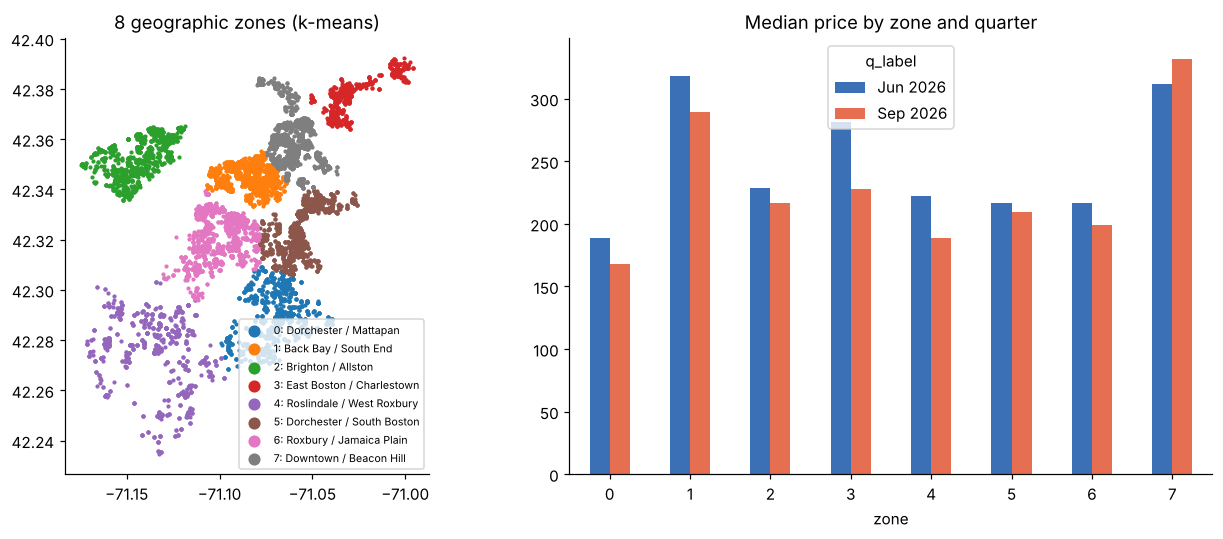

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for z in range(km.n_clusters):
    m = A["zone"] == z
    ax[0].scatter(A.loc[m, "longitude"], A.loc[m, "latitude"], s=3, label=f"{z}: {zone_names[z]}")
ax[0].set_aspect(1 / np.cos(np.radians(42.33))); ax[0].legend(fontsize=7, markerscale=4); ax[0].set_title("8 geographic zones (k-means)")
pv = A[A["price"].notna()].groupby(["zone", "q_label"])["price"].median().unstack()
pv.plot.bar(ax=ax[1], color=["#3b6fb6", "#e76f51"], rot=0); ax[1].set_title("Median price by zone and quarter")
plt.tight_layout(); plt.show()

## 3. Experimental design

The same listing usually appears in several quarters at a similar price. A random row split would put a listing's June row in training and its September row in test, so the model would only have to remember it. To prevent that, we **split by listing ID**: 20% of listings are held out, and none of their rows, in any quarter, are used for training.

Every experiment is scored on the same held-out listings, **separately for June and for September**.

In [5]:
P = A[A["price"].between(30, 2000)].copy()            # priced rows only (Jun + Sep)
P["y"] = np.log(P["price"])
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(P, groups=P["id"]))
TR, TE = P.iloc[tr_idx], P.iloc[te_idx]
assert not set(TR["id"]) & set(TE["id"])
print(TR.groupby("q_label").size().to_dict(), "train |", TE.groupby("q_label").size().to_dict(), "test")

def score(y_log, p_log):
    t, p = np.exp(y_log), np.exp(p_log)
    return {"MAE_$": mean_absolute_error(t, p), "R2_log": r2_score(y_log, p_log),
            "within_20%": np.mean(np.abs(p - t) / t <= .2) * 100, "bias_%": (np.median(p / t) - 1) * 100}

RF_PARAMS = dict(n_estimators=150, max_depth=14, min_samples_leaf=2, max_features=0.5, random_state=SEED, n_jobs=-1)

{'Jun 2026': 2875, 'Sep 2026': 2776} train | {'Jun 2026': 727, 'Sep 2026': 704} test


## 4. Step A: re-select the best model on June only

Before reusing Phase 1's choice, we re-run the method comparison (the four learned models; the baseline is already known to lose) on **June data alone**, with grouped 5-fold cross-validation on the June training listings.

In [6]:
jun_tr = TR[TR["quarter"] == "2026Q2"]
Xj, yj, gj = FULL_X.loc[jun_tr.index, BASE], jun_tr["y"], jun_tr["id"]
cands = {
    "Linear Regression": Pipeline([("s", StandardScaler()), ("m", LinearRegression())]),
    "Lasso": Pipeline([("s", StandardScaler()), ("m", LassoCV(alphas=np.logspace(-4, 0, 40), max_iter=50000))]),
    "Random Forest": RandomForestRegressor(**RF_PARAMS),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=600, learning_rate=0.06, max_depth=4, subsample=0.8, random_state=SEED),
}
june_cv = {n: -cross_val_score(m, Xj, yj, groups=gj, cv=GroupKFold(5), scoring="neg_root_mean_squared_error").mean()
           for n, m in cands.items()}
june_cv = pd.Series(june_cv).sort_values(); print("June-only CV RMSE(log):"); print(june_cv.round(4))
BEST = june_cv.idxmin(); print("lowest on June:", BEST)
gap = abs(june_cv["Random Forest"] - june_cv["Gradient Boosting"])
print(f"Random Forest vs Gradient Boosting gap: {gap:.4f} RMSE(log), well inside fold-to-fold noise")
MODEL_USED = "Random Forest"   # tie on June -> keep the Phase 1 winner (faster, needs less tuning)

June-only CV RMSE(log):
Gradient Boosting    0.3804
Random Forest        0.3806
Linear Regression    0.4506
Lasso                0.4515
dtype: float64
lowest on June: Gradient Boosting
Random Forest vs Gradient Boosting gap: 0.0003 RMSE(log), well inside fold-to-fold noise


**Reading.** On June, Random Forest and Gradient Boosting **tie**: the gap is a fraction of a thousandth, far smaller than the variation between folds. The linear models again trail by about 0.07. Because the two tree models tie, we keep **Random Forest**, the Phase 1 winner. It trains about 9× faster, needs less tuning, and its accuracy is the same.

## 5. Step B: train on June, apply to the whole year

We train the best model on June training listings with the Phase 1 features, then:
* score it on held-out **June** listings (same quarter) and held-out **September** listings (a later quarter it never saw);
* price the full **December, March, June and September** listing stock to see how the predicted market level moves.

In [7]:
def fit_rf(rows, cols, weight=None):
    return RandomForestRegressor(**RF_PARAMS).fit(FULL_X.loc[rows.index, cols], rows["y"], sample_weight=weight)

june_model = fit_rf(jun_tr, BASE)
rows = []
for q, lab in [("2026Q2", "Jun 2026"), ("2026Q3", "Sep 2026")]:
    te = TE[TE["quarter"] == q]
    rows.append({"experiment": "June-only model", "test quarter": lab, **score(te["y"], june_model.predict(FULL_X.loc[te.index, BASE]))})
pd.DataFrame(rows).round(2)

,experiment,test quarter,MAE_$,R2_log,within_20%,bias_%
0,June-only model,Jun 2026,94.95,0.77,51.31,3.71
1,June-only model,Sep 2026,100.61,0.62,38.07,12.48


The June model **over-prices September by about 12%** (median bias), and its September error is clearly worse than its June error. The listing features are unchanged; the market moved. Boston's June peak (graduations, summer tourism) cools by September, and a single-snapshot model has no way to know that.

In [8]:
# Price the whole listing stock in every quarter with the June model (Dec and Mar have no truth to compare)
stock = []
for q, lab, *_ in QUARTERS:
    d = A[A["quarter"] == q]
    pred = np.exp(june_model.predict(FULL_X.loc[d.index, BASE]))
    stock.append({"quarter": lab, "listings": len(d), "actual_median": d["price"].median(),
                  "june_model_median": np.median(pred)})
stock = pd.DataFrame(stock); stock

,quarter,listings,actual_median,june_model_median
0,Dec 2025,3706,NaN,295.483177
1,Mar 2026,1881,NaN,374.249248
2,Jun 2026,4414,279.0,294.833967
3,Sep 2026,4368,253.0,301.546822


**Pricing the full stock.** For December and March there is no truth to compare against. The predicted median shows how the *mix* of listings changes. The March scrape is partial and skewed toward entire homes (76% vs about 68% in other quarters), so its predicted median is much higher. That reflects which listings were captured, not a market shift.

## 6. Step C: pool the quarters and add time + zone

All models below are Random Forests with the tuned Phase 1 settings. Only the training rows and the feature set change:

| Experiment | Training rows | Features |
|---|---|---|
| June-only | Jun | 48 snapshot |
| Sep-only | Sep | 48 snapshot |
| Pooled | Jun + Sep | 48 snapshot |
| Pooled + time | Jun + Sep | + quarter, tenure, review recency |
| Pooled + time + zone | Jun + Sep | + rings and 8 zones |
| … + recency weighting | Jun + Sep | same, Sep rows weighted 2× |

In [9]:
sep_tr = TR[TR["quarter"] == "2026Q3"]
experiments = {
    "June-only": (jun_tr, BASE, None),
    "Sep-only": (sep_tr, BASE, None),
    "Pooled": (TR, BASE, None),
    "Pooled + time": (TR, BASE + TIME, None),
    "Pooled + time + zone": (TR, BASE + TIME + ZONE, None),
    "Pooled + time + zone, recency-weighted": (TR, BASE + TIME + ZONE, np.where(TR["quarter"] == "2026Q3", 2.0, 1.0)),
}
models, rows = {}, []
for name, (rws, cols, w) in experiments.items():
    t0 = time.time(); m = fit_rf(rws, cols, w); models[name] = (m, cols)
    for q, lab in [("2026Q2", "Jun 2026"), ("2026Q3", "Sep 2026")]:
        te = TE[TE["quarter"] == q]
        rows.append({"experiment": name, "test": lab, **score(te["y"], m.predict(FULL_X.loc[te.index, cols]))})
exp = pd.DataFrame(rows)
exp_wide = exp.pivot(index="experiment", columns="test", values=["MAE_$", "R2_log", "bias_%", "within_20%"]).loc[list(experiments)]
exp_wide.round(2)

MAE_$            R2_log           \
test                                   Jun 2026 Sep 2026 Jun 2026 Sep 2026   
experiment                                                                   
June-only                                 94.95   100.61     0.77     0.62   
Sep-only                                 112.63    85.03     0.67     0.75   
Pooled                                    95.87    86.56     0.76     0.74   
Pooled + time                             95.25    84.97     0.78     0.75   
Pooled + time + zone                      94.92    84.89     0.78     0.76   
Pooled + time + zone, recency-weighted    96.63    83.21     0.77     0.76   

                                         bias_%          within_20%           
test                                   Jun 2026 Sep 2026   Jun 2026 Sep 2026  
experiment                                                                    
June-only                                  3.71    12.48      51.31    38.07  
Sep-only                                  -5.04     4.73      42.50    49.01  
Pooled                                    -0.48     7.13      49.11    49.57  
Pooled + time                              1.34     5.00      49.79    50.43  
Pooled + time + zone                       2.19     5.35      50.62    50.28  
Pooled + time + zone, recency-weighted     0.47     5.08      49.38    50.57

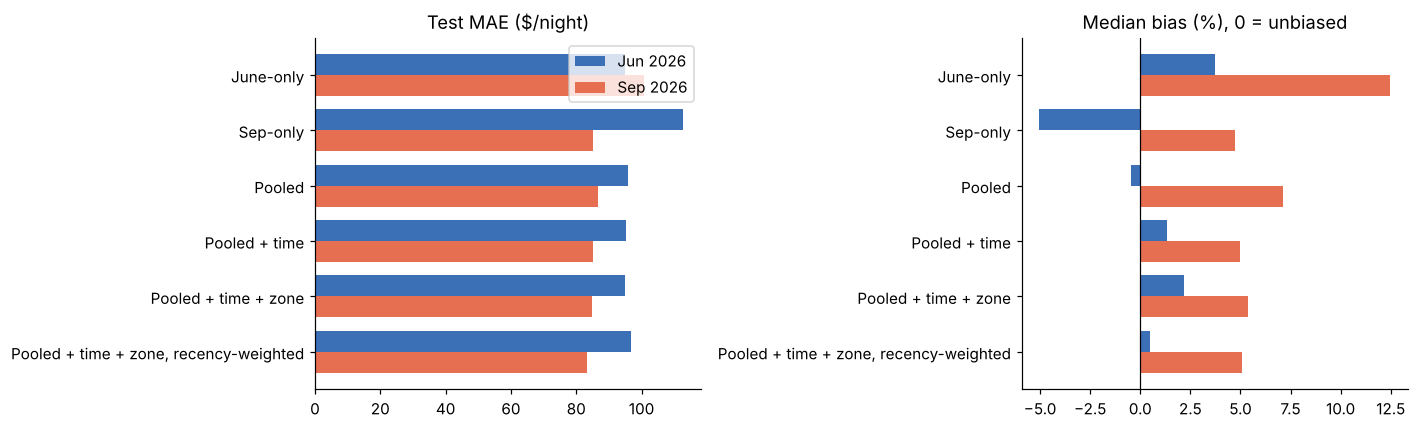

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
names = list(experiments)
for k, (metric, title) in enumerate([("MAE_$", "Test MAE ($/night)"), ("bias_%", "Median bias (%), 0 = unbiased")]):
    w = 0.38
    for j, (lab, c) in enumerate([("Jun 2026", "#3b6fb6"), ("Sep 2026", "#e76f51")]):
        v = exp[exp["test"] == lab].set_index("experiment").loc[names, metric]
        ax[k].barh(np.arange(len(names)) + (j - .5) * w, v, height=w, color=c, label=lab)
    ax[k].set_yticks(range(len(names)), names); ax[k].set_title(title); ax[k].invert_yaxis()
ax[1].axvline(0, color="k", lw=.8); ax[0].legend()
plt.tight_layout(); plt.show()

## 7. Step D: how parameter weights change between quarters

A **Lasso fitted separately on each priced quarter** (all priced rows of that quarter) gives one weight per feature per quarter. Converting each to a "% price effect" shows which levers strengthened or weakened from June to September. The pooled Random Forest's permutation importance shows how much the new time and zone features are actually used.

In [11]:
def lasso_effects(rows, cols):
    pipe = Pipeline([("s", StandardScaler()), ("m", LassoCV(alphas=np.logspace(-4, 0, 40), max_iter=50000))])
    pipe.fit(FULL_X.loc[rows.index, cols], rows["y"])
    raw = pipe.named_steps["m"].coef_ / pipe.named_steps["s"].scale_
    return pd.Series((np.exp(raw) - 1) * 100, cols)

eff = pd.DataFrame({lab: lasso_effects(P[P["quarter"] == q], BASE) for q, lab in [("2026Q2", "Jun 2026"), ("2026Q3", "Sep 2026")]})
SHOW = ["private_room", "hotel_room", "monthly", "log_min_nights", "bedrooms", "log_reviews", "reviews_per_month",
        "log_host_listings", "availability_365", "licensed", "dist_km", "kw_luxury", "kw_view", "kw_parking",
        "nb_Back Bay", "nb_Downtown", "nb_South Boston Waterfront", "nb_Dorchester", "nb_Fenway"]
weights = eff.loc[SHOW].round(1); weights["change_pts"] = (weights["Sep 2026"] - weights["Jun 2026"]).round(1)
weights.sort_values("change_pts")

,Jun 2026,Sep 2026,change_pts
monthly,58.9,-9.6,-68.5
licensed,29.9,8.0,-21.9
kw_luxury,15.6,10.5,-5.1
bedrooms,23.7,18.9,-4.8
nb_Back Bay,4.9,1.4,-3.5
kw_parking,0.5,-2.0,-2.5
dist_km,-2.5,-4.2,-1.7
log_host_listings,-8.8,-9.1,-0.3
log_reviews,-4.6,-4.8,-0.2
availability_365,0.0,0.0,0.0


final model: Pooled + time + zone, recency-weighted


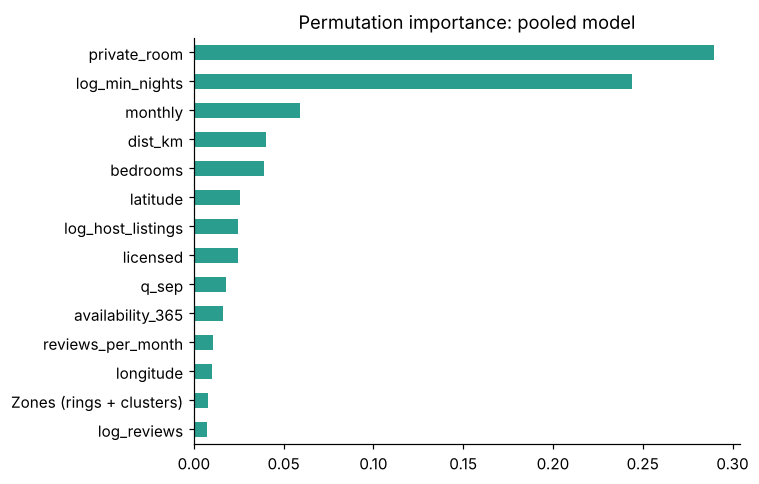

In [12]:
final_name = exp[exp["test"] == "Sep 2026"].set_index("experiment")["MAE_$"].idxmin()
final_model, final_cols = models[final_name]
te_all = TE
pi = permutation_importance(final_model, FULL_X.loc[te_all.index, final_cols], te_all["y"], n_repeats=5,
                            random_state=SEED, scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, final_cols)
grp = {"Neighbourhood (one-hot)": [c for c in final_cols if c.startswith("nb_")],
       "Zones (rings + clusters)": [c for c in final_cols if c in ZONE]}
imp_g = imp.drop([c for g in grp.values() for c in g])
for g, cs in grp.items():
    imp_g[g] = imp[cs].sum()
imp_g = imp_g.sort_values(ascending=False)
print("final model:", final_name)
imp_g.head(14).sort_values().plot.barh(figsize=(7, 4.5), color="#2a9d8f", title="Permutation importance: pooled model"); plt.tight_layout(); plt.show()

## 8. Verdict for Phase 2

In [13]:
j = exp.set_index(["experiment", "test"])
jo, fin = j.loc[("June-only", "Sep 2026")], j.loc[(final_name, "Sep 2026")]
print(f"September MAE  June-only model: ${jo['MAE_$']:.0f} (bias {jo['bias_%']:+.1f}%)  ->  {final_name}: ${fin['MAE_$']:.0f} (bias {fin['bias_%']:+.1f}%)")
print(f"Improvement on September: {1 - fin['MAE_$'] / jo['MAE_$']:.0%}")

September MAE  June-only model: $101 (bias +12.5%)  ->  Pooled + time + zone, recency-weighted: $83 (bias +5.1%)
Improvement on September: 17%


* **A snapshot model goes stale.** Trained on June, the model's September error rises from about $95 to about $101 per night, and it over-prices September by about 12%. It still ranks listings well, but it misses the *level*, because the market cooled after the June peak.
* **Using every quarter helps most; time and zone add a smaller gain.** Pooling Jun + Sep does most of the work. Time features (quarter, tenure, review recency) and zone features each trim a little more, and weighting the newer quarter 2× gives the best September error, about **17% below the June-only model**. The pooled models also stay accurate on June, which a September-only model does not.
* **Weights move between quarters.** In the per-quarter Lasso, the premium for a licensed listing falls from about +30% to +8%, and the premiums for Downtown, Fenway and "view" listings grow. The minimum-stay effects (`log_min_nights` and `monthly` should be read together) also shift. A fixed set of weights can't serve all year, which is why the pooled model learns with a time dimension.
* **Some bias remains (about +5% on September).** With only two priced quarters, the model has one seasonal contrast to learn from. Priced December and March files would let `q_sep` become a proper season feature.
* **Recommendation:** use the pooled time + zone Random Forest with recency weighting, and re-fit it every quarter as each new snapshot arrives.

## 9. Export to the interface

In [14]:
FINE = {final_cols.index(c) for c in ("latitude", "longitude", "dist_km")}

def export_tree(t):
    tr = t.tree_; leaf = tr.children_left == -1
    assert np.all(tr.children_left[~leaf] == np.arange(tr.node_count)[~leaf] + 1)
    # coordinate splits need 9 significant digits; other thresholds 6; leaf values (log price) 5
    x = [float(f"{v:.5g}") if is_leaf else float(f"{th:.9g}" if f in FINE else f"{th:.6g}")
         for v, th, f, is_leaf in zip(tr.value[:, 0, 0], tr.threshold, tr.feature, leaf)]
    return {"f": np.where(leaf, -1, tr.feature).tolist(), "x": x}

# refit the chosen pooled model on ALL priced rows
w_all = np.where(P["quarter"] == "2026Q3", 2.0, 1.0) if "recency" in final_name else None
deploy = RandomForestRegressor(**RF_PARAMS).fit(FULL_X.loc[P.index, final_cols], P["y"], sample_weight=w_all)
ref = P.sample(150, random_state=1)

quarterly = {
    "quarters": [{"code": q, "label": lab, "listings": int((A["quarter"] == q).sum()),
                  "priced": int(A.loc[A["quarter"] == q, "price"].notna().sum()),
                  "actual_median": None if np.isnan(m := A.loc[A["quarter"] == q, "price"].median()) else float(m),
                  "june_model_median": float(stock.loc[stock["quarter"] == lab, "june_model_median"].iloc[0]),
                  "entire_share": float((A.loc[A["quarter"] == q, "room_type"] == "Entire home/apt").mean())}
                 for q, lab, *_ in QUARTERS],
    "june_cv": june_cv.round(4).to_dict(), "best_on_june": BEST,
    "experiments": exp.round(3).to_dict(orient="records"), "experiment_order": names, "final": final_name,
    "weights": weights.reset_index().rename(columns={"index": "feature"}).to_dict(orient="records"),
    "importance": imp_g.head(14).round(5).to_dict(),
    "zones": {"centers_km": km.cluster_centers_.round(5).tolist(), "names": {int(k): v for k, v in zone_names.items()}},
    "zone_price": {f"{int(z)}|{lab}": float(v) for (z, lab), v in P.groupby(["zone", "q_label"])["price"].median().items()},
    "features": final_cols,
    "band_log": [float(np.quantile(r := TE["y"] - final_model.predict(FULL_X.loc[TE.index, final_cols]), .10)), float(np.quantile(r, .90))],
    "center": CENTER, "n_zones": int(km.n_clusters),
}
js = (OUT / "data.js").read_text()
bundle = json.loads(js[js.index("{"): js.rindex("}") + 1])
bundle["quarterly"] = quarterly
payload = json.dumps(bundle, separators=(",", ":"))
(OUT / "data.js").write_text("window.PRICING = " + payload + ";\n")

mjs = (OUT / "models.js").read_text()
mbundle = json.loads(mjs[mjs.index("{"): mjs.rindex("}") + 1])
mbundle["quarterly"] = {"trees": [export_tree(e) for e in deploy.estimators_]}
mbundle["quarterly_reference"] = {"X": FULL_X.loc[ref.index, final_cols].values.tolist(),
                                  "pred": np.round(deploy.predict(FULL_X.loc[ref.index, final_cols]), 6).tolist()}
mpayload = json.dumps(mbundle, separators=(",", ":"))
(OUT / "models.js").write_text("window.PRICING_MODELS = " + mpayload + ";\n")
print(f"data.js {len(payload) / 1e6:.2f} MB, models.js {len(mpayload) / 1e6:.2f} MB")

data.js 0.24 MB, models.js 5.74 MB
